In [58]:
from tbparse import SummaryReader
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
import glob 
import scienceplots

print("Current working directory:", pathlib.Path.cwd().parent.parent)

source_dir = pathlib.Path.cwd().parent.parent
print("Source directory:", source_dir)
# make a list of all events in the log file
from pathlib import Path
source_dir = str(source_dir)

source_dir = source_dir + "/scripts/rsl_rl/logs/rsl_rl/symmetry/"
print("Source directory with logs:", source_dir)

sns.set_style("whitegrid")  # Choose your style
# sns.set_context("paper", font_scale=1.5)
plt.style.use(['science', 'ieee'])
# plt.rcParams.update({'font.size': 20})
# sns.set_style("whitegrid")  # Choose your style
# sns.set_context("paper")    
# sns.color_palette("colorblind")
# collect all dirs
paths = sorted(glob.glob(source_dir + "/*/events*"))
print(paths)

Current working directory: /home/vikas-admin/Codebases/SPEAR/MetaRL/ss26-drone-control
Source directory: /home/vikas-admin/Codebases/SPEAR/MetaRL/ss26-drone-control
Source directory with logs: /home/vikas-admin/Codebases/SPEAR/MetaRL/ss26-drone-control/scripts/rsl_rl/logs/rsl_rl/symmetry/
[]


With tensorboard dataframes

In [66]:
tasks = ["baselines", 
        #  "aug_only",
        #  "aug_only_c4", 
        #  "mirror_loss_only", 
         "aug_plus_mirror_loss", 
        #  "slalom"
         ]

In [67]:
from tensorboard.backend.event_processing import event_accumulator
import pandas as pd
import os

def extract_scalars(log_dir, task, run_id):
    ea = event_accumulator.EventAccumulator(log_dir)
    ea.Reload()
    data = []
    for tag in ea.Tags()["scalars"]:
        for s in ea.Scalars(tag):
            data.append({
                "step": s.step,
                "value": s.value,
                "tag": tag,
                # "algorithm": algorithm,
                "task": task,
                "run": run_id
            })
    return pd.DataFrame(data)

# Aggregate all logs
base_dir = source_dir
all_dfs = []
# for algorithm in ["baseline", "randomised"]:
for task in tasks:
    task= f"{task}"
    # if algorithm=="randomised":
        # task=f"{task}_rand"
    task_dir = os.path.join(base_dir, task)
    for run in os.listdir(task_dir):
        log_path = os.path.join(task_dir, run)
        df = extract_scalars(log_path, task, run)
        all_dfs.append(df)

full_df = pd.concat(all_dfs)


In [68]:
print("Unique tags in the data:", full_df['tag'].unique())

summary = (
    full_df.query("tag == 'Train/mean_reward'")
)
summary.head()

Unique tags in the data: ['Episode_Reward/lin_vel' 'Episode_Reward/ang_vel'
 'Episode_Reward/distance_to_goal' 'Episode_Termination/died'
 'Episode_Termination/time_out' 'Metrics/final_distance_to_goal'
 'Loss/value_function' 'Loss/surrogate' 'Loss/entropy'
 'Loss/learning_rate' 'Policy/mean_noise_std' 'Perf/total_fps'
 'Perf/collection time' 'Perf/learning_time' 'Train/mean_reward'
 'Train/mean_episode_length' 'Train/mean_reward/time'
 'Train/mean_episode_length/time' 'Loss/symmetry']


,step,value,tag,task,run
4200,0,-28.001949,Train/mean_reward,baselines,2026-04-24_10-51-08
4201,1,-22.994467,Train/mean_reward,baselines,2026-04-24_10-51-08
4202,2,-24.463717,Train/mean_reward,baselines,2026-04-24_10-51-08
4203,3,-30.690971,Train/mean_reward,baselines,2026-04-24_10-51-08
4204,4,-23.568102,Train/mean_reward,baselines,2026-04-24_10-51-08


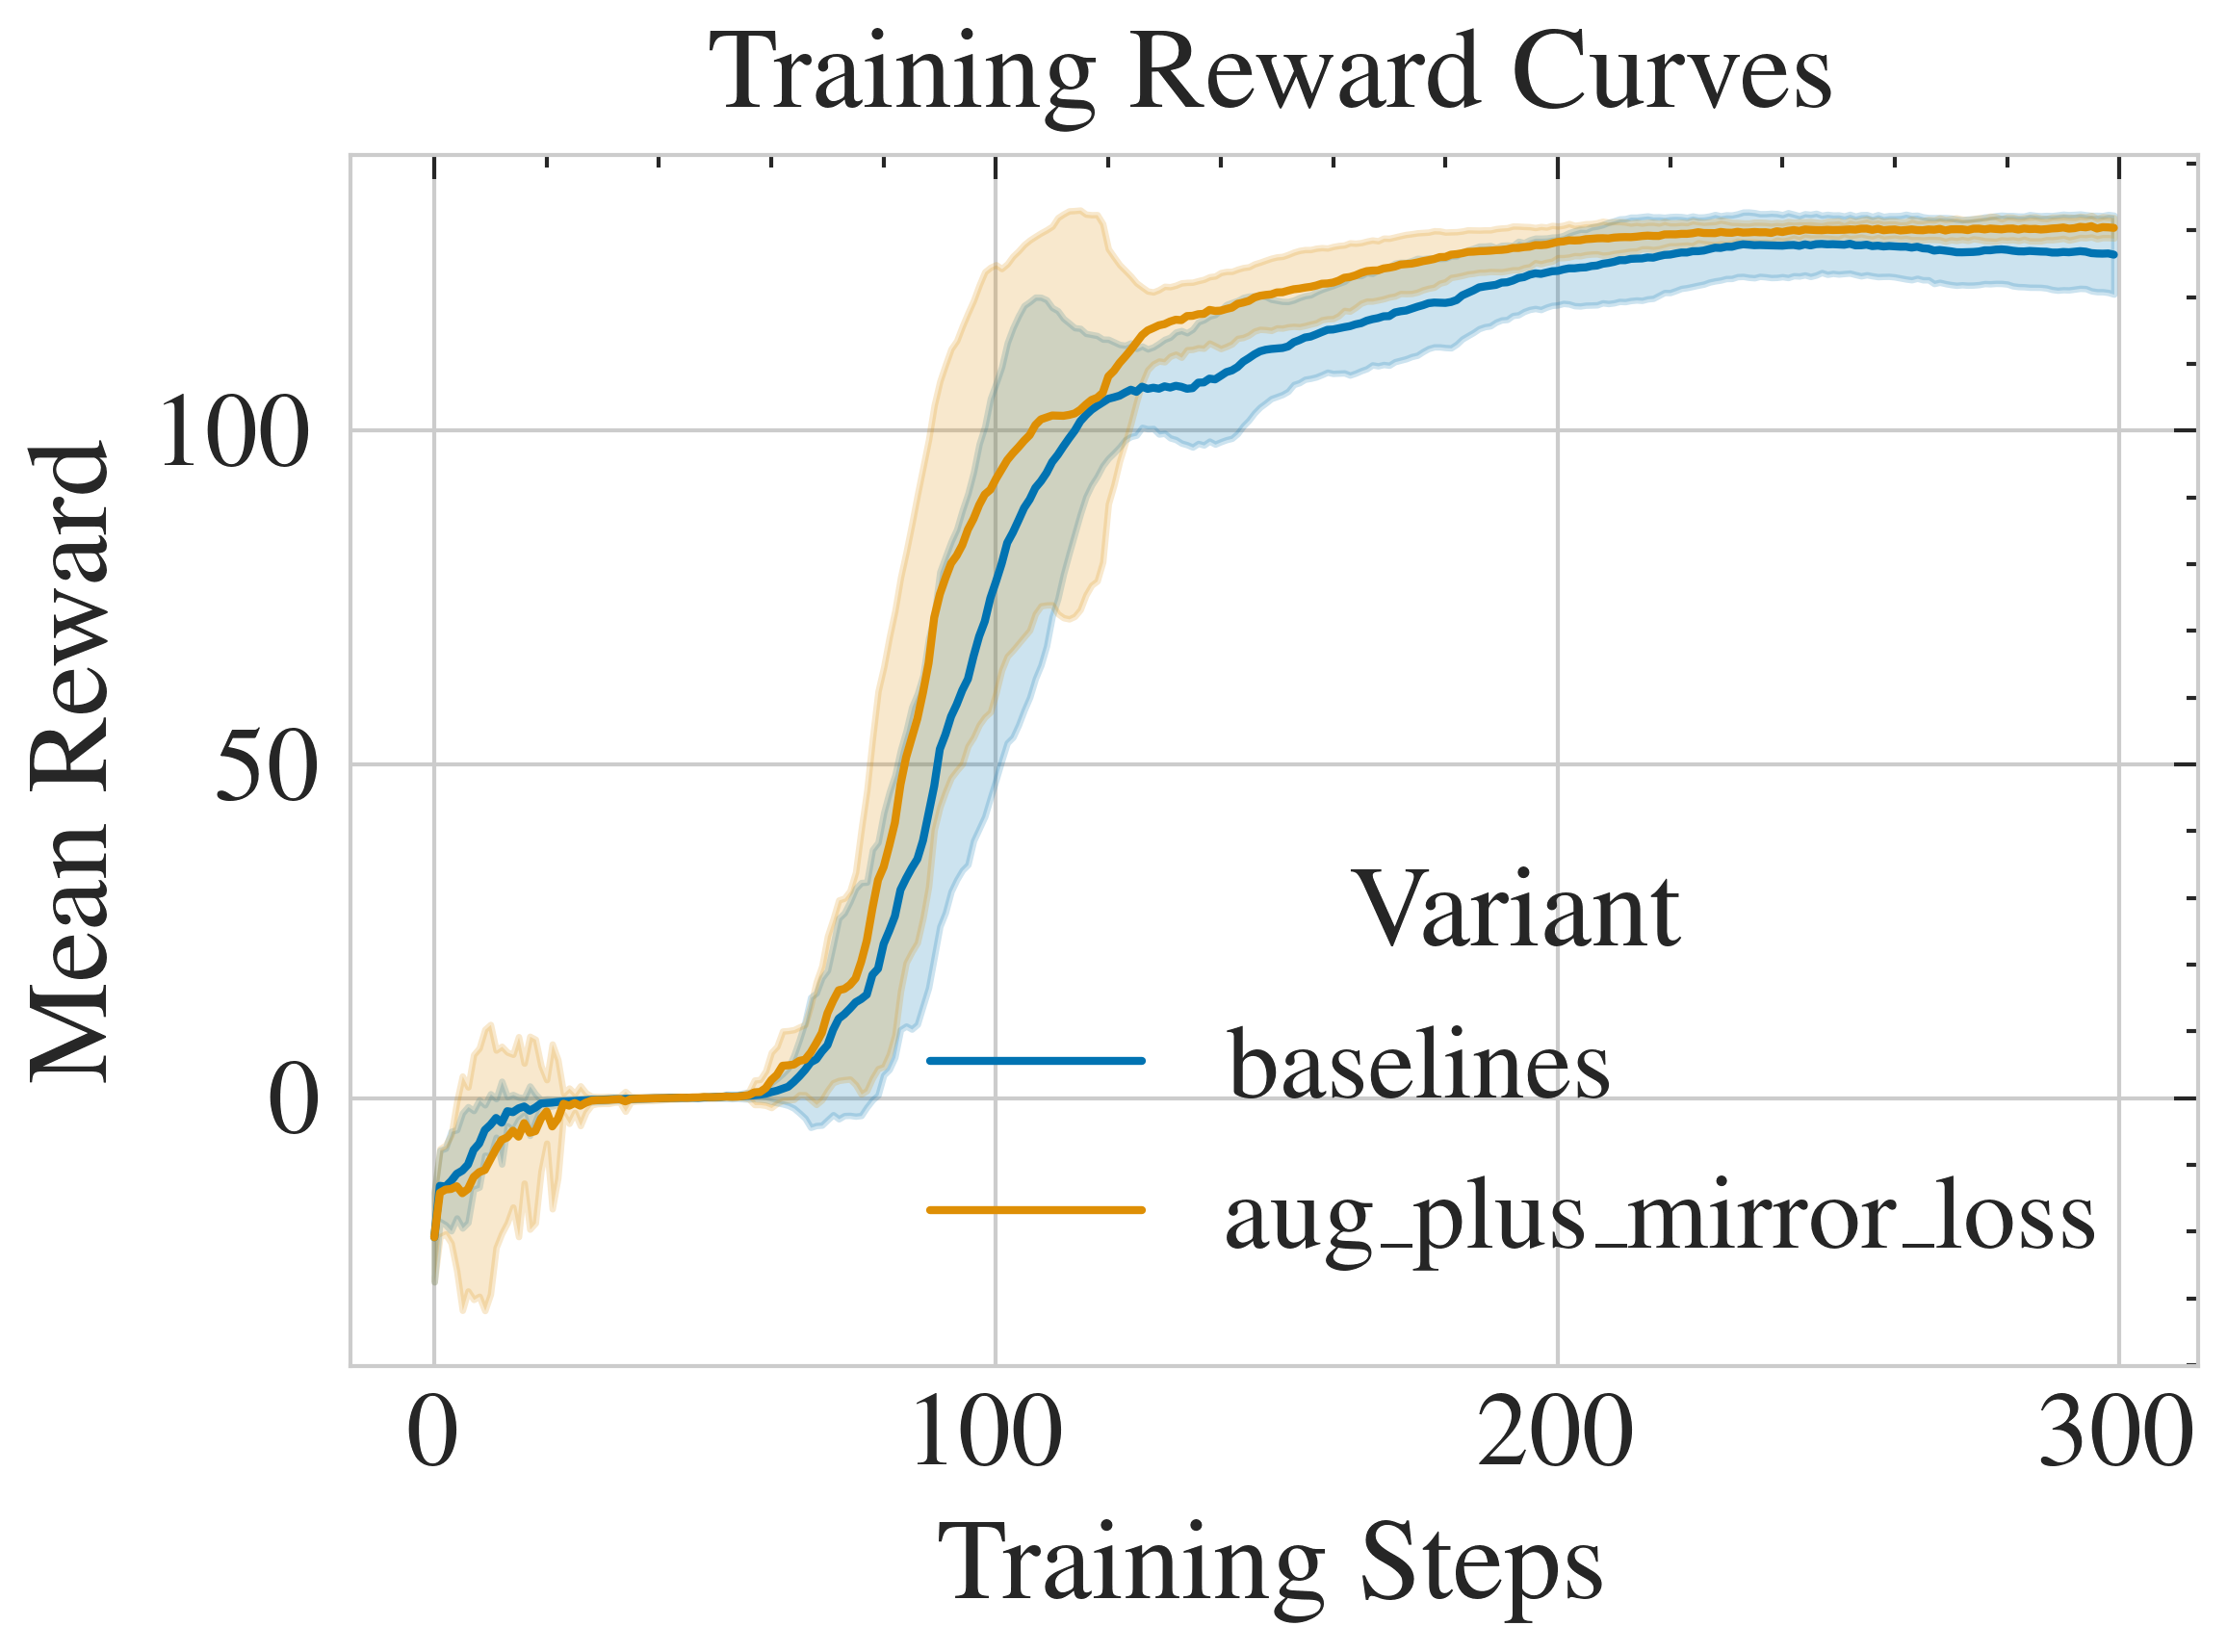

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

# sns.set_context("paper", font_scale=1.8)

formats = ['pdf', 'png']

# set a color palette
sns.set_palette("colorblind")

plt.figure(figsize=(4, 3))
sns.lineplot(data=summary, x="step", y="value", hue="task", errorbar="sd")
plt.title("Training Reward Curves")
plt.xlabel("Training Steps")
plt.ylabel("Mean Reward")
plt.legend(title="Variant")
plt.tight_layout()
# plt.show()

# for fmt in formats:
     # plt.savefig(f"log_figures/symmetry/training_reward_curves.{fmt}", dpi=300)
# plt.savefig("log_figures/symmetry/training_reward_curves.jpg", dpi=300)


## Rliable

In [53]:
from rliable import library as rly
from rliable import metrics
from rliable import plot_utils
import numpy as np

#@title Plotting: Seaborn style and matplotlib params
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_style("white")

# Matplotlib params
from matplotlib import rcParams
from matplotlib import rc

rcParams['legend.loc'] = 'best'
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

rc('text', usetex=False)

In [47]:
# create reward dataframe to be used with rliable
summary.head()

# aggreate reward over the last 50 steps for each run
final_rewards = summary.groupby(["task", "run"]).apply(lambda x: x.sort_values("step").tail(50)["value"].mean()).reset_index(name="final_reward")
print(final_rewards)
# drop run column
final_rewards = final_rewards.drop(columns=["run"])
print(final_rewards)

         task                  run  final_reward
0    aug_only  2026-04-24_11-33-48    125.711537
1    aug_only  2026-04-24_11-37-05    130.298191
2    aug_only  2026-04-24_11-40-11    132.893263
3    aug_only  2026-04-24_13-44-24    133.476084
4    aug_only  2026-04-24_13-47-29    130.711701
5    aug_only  2026-04-24_13-50-28    131.556728
6    aug_only  2026-04-24_13-53-29    132.258286
7    aug_only  2026-04-24_13-56-29    131.148395
8    aug_only  2026-04-24_13-59-29    129.739622
9    aug_only  2026-04-24_14-02-46    133.765649
10   aug_only  2026-04-24_14-05-56    133.966914
11  baselines  2026-04-24_10-51-08    125.312041
12  baselines  2026-04-24_10-53-23    132.176368
13  baselines  2026-04-24_10-55-33    132.305947
14  baselines  2026-04-24_13-42-52    117.058832
15  baselines  2026-04-24_13-45-11    132.197694
16  baselines  2026-04-24_13-48-09    125.003018
17  baselines  2026-04-24_13-51-08    125.900643
18  baselines  2026-04-24_13-54-07    128.229999
19  baselines  2026-

/tmp/ipykernel_84393/2624729464.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  final_rewards = summary.groupby(["task", "run"]).apply(lambda x: x.sort_values("step").tail(50)["value"].mean()).reset_index(name="final_reward")


In [50]:
# make a dataframe with the final rewards for each task and run , don't need run as a column
final_rewards

# nomralise the final rewards by the min and max reward achieved across all runs and tasks
min_reward = final_rewards["final_reward"].min()
max_reward = final_rewards["final_reward"].max()
final_rewards["normalized_final_reward"] = (final_rewards["final_reward"] - min_reward) / (max_reward - min_reward)
print(final_rewards)

         task  final_reward  normalized_final_reward
0    aug_only    125.711537                 0.511750
1    aug_only    130.298191                 0.783020
2    aug_only    132.893263                 0.936501
3    aug_only    133.476084                 0.970971
4    aug_only    130.711701                 0.807476
5    aug_only    131.556728                 0.857454
6    aug_only    132.258286                 0.898946
7    aug_only    131.148395                 0.833303
8    aug_only    129.739622                 0.749984
9    aug_only    133.765649                 0.988097
10   aug_only    133.966914                 1.000000
11  baselines    125.312041                 0.488122
12  baselines    132.176368                 0.894101
13  baselines    132.305947                 0.901765
14  baselines    117.058832                 0.000000
15  baselines    132.197694                 0.895362
16  baselines    125.003018                 0.469845
17  baselines    125.900643                 0.

In [52]:
#@title Stratified Bootstrap CIs and Aggregate metrics

StratifiedBootstrap = rly.StratifiedBootstrap

IQM = lambda x: metrics.aggregate_iqm(x) # Interquartile Mean
OG = lambda x: metrics.aggregate_optimality_gap(x, 1.0) # Optimality Gap
MEAN = lambda x: metrics.aggregate_mean(x)
MEDIAN = lambda x: metrics.aggregate_median(x)

In [ ]:
#@title Score helpers -- Subsampling


def subsample_scores(score_dict, n=5, replace=False):
  subsampled_dict = {}
  total_samples = len(score_dict[list(score_dict.keys())[0]])
  for game, scores in score_dict.items():
    indices = np.random.choice(range(total_samples), size=n, replace=replace)
    subsampled_dict[game] = scores[indices]
  return subsampled_dict

def subsample_scores_mat(score_mat, num_samples=5, replace=False):
  subsampled_dict = []
  total_samples, num_games = score_mat.shape
  subsampled_scores = np.empty((num_samples, num_games))
  for i in range(num_games):
    indices = np.random.choice(total_samples, size=num_samples, replace=replace)
    subsampled_scores[:, i] = score_mat[indices, i]
  return subsampled_scores

def subsample_seeds(score_mat, num_samples=5, replace=False):
  indices = np.random.choice(
      score_mat.shape[0], size=num_samples, replace=replace)
  return score_mat[indices]

def batch_subsample_seeds(score_mat, num_samples=5, batch_size=100,
                          replace=False):
  indices = [
    np.random.choice(score_mat.shape[0], size=num_samples, replace=replace)
    for _ in range(batch_size)
  ]
  return (score_mat[idx] for idx in indices)

def subsample_scores_mat_with_replacement(score_mat, num_samples=5):
  subsampled_dict = []
  total_samples, num_games = score_mat.shape
  indices = np.random.choice(
      total_samples, size=(num_samples, num_games), replace=True)
  col_indices =  np.expand_dims(np.arange(num_games), axis=0)
  col_indices = np.repeat(col_indices, num_samples, axis=0)
  subsampled_scores = score_mat[indices, col_indices]
  return subsampled_scores

In [ ]:
#@title Aggregate computation helpers

SIZES = [3, 5, 10, 25, 50, 100]

def calc_aggregate_fn(score_data, num_samples=5, total_n=20000, 
                      aggregate_fn=MEDIAN, replace=False):
  subsampled_scores = batch_subsample_seeds(
      score_data, num_samples, batch_size=total_n, replace=replace)
  aggregates = [aggregate_fn(scores) for scores in subsampled_scores]
  return np.array(aggregates)

def calculate_aggregate_varying_sizes(score_matrix, aggregate_fn, total_n=20000,
                                      sizes=None, replace=False):
  agg_dict = {}
  if sizes is None:
    sizes = SIZES
  for size in sizes:
    agg_dict[n] = calc_aggregate_fn(score_matrix, num_samples=size, aggregate_fn=aggregate_fn,
                                    total_n=total_n, replace=replace)
    print('Mean Aggregate: {}'.format(np.mean(agg_dict[n])))
  return agg_dict

def CI(bootstrap_dist, stat_val=None, alpha=0.05, is_pivotal=False):
    """
    Get the bootstrap confidence interval for a given distribution.
    Args:
      bootstrap_distribution: numpy array of bootstrap results.
      stat_val: The overall statistic that this method is attempting to
        calculate error bars for. Default is None.
      alpha: The alpha value for the confidence intervals.
      is_pivotal: if true, use the pivotal (reverse percentile) method. 
        If false, use the percentile method.
    Returns:
      (low, high): The lower and upper limit for `alpha` x 100% CIs.
      val: The median value of the bootstrap distribution if `stat_val` is None
        else `stat_val`.
    """
    # Adapted from https://pypi.org/project/bootstrapped
    if is_pivotal:
      assert stat_val is not None, 'Please pass the statistic for a pivotal'
      'confidence interval' 
      low = 2 * stat_val - np.percentile(bootstrap_dist, 100 * (1 - alpha / 2.))
      val = stat_val
      high = 2 * stat_val - np.percentile(bootstrap_dist, 100 * (alpha / 2.))
    else:
      low = np.percentile(bootstrap_dist, 100 * (alpha / 2.))
      val = np.percentile(bootstrap_dist, 50)
      high = np.percentile(bootstrap_dist, 100 * (1 - alpha / 2.))
    return (low, high), val

In [ ]:
#@title Aggregates on Atari 100K (with 10 runs)


aggregate_func = lambda x: np.array([MEDIAN(x), IQM(x), MEAN(x), OG(x)])
aggregate_scores, aggregate_interval_estimates = rly.get_interval_estimates(
    atari_100k_score_dict, aggregate_func, reps=50000)

algorithms = ['SimPLe', 'DER', 'OTR', 'CURL', 'DrQ', 'DrQ(ε)', 'SPR']
fig, axes = plot_utils.plot_interval_estimates(
    aggregate_scores, 
    aggregate_interval_estimates,
    metric_names = ['Median', 'IQM', 'Mean', 'Optimality Gap'],
    algorithms=algorithms,
    colors=ATARI_100K_COLOR_DICT,
    xlabel_y_coordinate=-0.16,
    xlabel='Human Normalized Score')
plt.show()
save_fig(fig, 'atari_100k_aggregates')

## Reward distribution for each task